# Weather Data Analysis Using NumPy, Pandas, and Matplotlib

**Project objective:** Analyze historical weather data to explore temperature, humidity, precipitation, monthly and seasonal patterns, and extreme weather days.

**Libraries:** Pandas, NumPy, Matplotlib, Requests
**Data Source:** Kaggle Weather Historical Dataset
**Period:** 2015–2025

## 1. Import the required libraries

- **Pandas:** load, clean, organize, and group data.
- **NumPy:** calculate statistics and filter extreme values.
- **Matplotlib:** create charts.
- **Seaborn:** creating visually appealing charts.

In [ ]:
# mount drive

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully")

Libraries imported successfully


## 2. Load historical weather data

We have downloaded weather historical data from kaggle.


In [ ]:
weather_df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/GlobalWeatherRepository.csv')

print("Dataset Loaded Successfully")
print(f'Number of rows: {weather_df.shape[0]}')
print(f'Number of columns:{weather_df.shape[1]}')

display(weather_df.head())

Dataset Loaded Successfully
Number of rows: 170538
Number of columns:41


,country,location_name,latitude,longitude,timezone,last_updated_epoch,last_updated,temperature_celsius,temperature_fahrenheit,condition_text,...,air_quality_PM2.5,air_quality_PM10,air_quality_us-epa-index,air_quality_gb-defra-index,sunrise,sunset,moonrise,moonset,moon_phase,moon_illumination
0,Afghanistan,Kabul,34.52,69.18,Asia/Kabul,1715849100,5/16/2024 13:15,26.6,79.8,Partly Cloudy,...,8.4,26.6,1,1,4:50 AM,6:50 PM,12:12 PM,1:11 AM,Waxing Gibbous,55
1,Albania,Tirana,41.33,19.82,Europe/Tirane,1715849100,5/16/2024 10:45,19.0,66.2,Partly cloudy,...,1.1,2.0,1,1,5:21 AM,7:54 PM,12:58 PM,2:14 AM,Waxing Gibbous,55
2,Algeria,Algiers,36.76,3.05,Africa/Algiers,1715849100,5/16/2024 9:45,23.0,73.4,Sunny,...,10.4,18.4,1,1,5:40 AM,7:50 PM,1:15 PM,2:14 AM,Waxing Gibbous,55
3,Andorra,Andorra La Vella,42.50,1.52,Europe/Andorra,1715849100,5/16/2024 10:45,6.3,43.3,Light drizzle,...,0.7,0.9,1,1,6:31 AM,9:11 PM,2:12 PM,3:31 AM,Waxing Gibbous,55
4,Angola,Luanda,-8.84,13.23,Africa/Luanda,1715849100,5/16/2024 9:45,26.0,78.8,Partly cloudy,...,183.4,262.3,5,10,6:12 AM,5:55 PM,1:17 PM,12:38 AM,Waxing Gibbous,55


## 3. Initial Data Inspection


*   Understand the structure and quality of data
*   Check the datatypes of columns, assign appropriate datatypes, inspect missing and duplicate values







In [ ]:
print("Column Names:")
print(weather_df.columns.to_list())

print("\nData Types:")
print(weather_df.dtypes)

print("\nDataset Information:")
print(weather_df.info())

print("\nMissing Values:")
print(weather_df.isnull().sum())

print("\nDuplicate Values")
print(weather_df.duplicated().sum())

print("\nDescriptive Summary")
print(weather_df.describe)

Column Names:
['country', 'location_name', 'latitude', 'longitude', 'timezone', 'last_updated_epoch', 'last_updated', 'temperature_celsius', 'temperature_fahrenheit', 'condition_text', 'wind_mph', 'wind_kph', 'wind_degree', 'wind_direction', 'pressure_mb', 'pressure_in', 'precip_mm', 'precip_in', 'humidity', 'cloud', 'feels_like_celsius', 'feels_like_fahrenheit', 'visibility_km', 'visibility_miles', 'uv_index', 'gust_mph', 'gust_kph', 'air_quality_Carbon_Monoxide', 'air_quality_Ozone', 'air_quality_Nitrogen_dioxide', 'air_quality_Sulphur_dioxide', 'air_quality_PM2.5', 'air_quality_PM10', 'air_quality_us-epa-index', 'air_quality_gb-defra-index', 'sunrise', 'sunset', 'moonrise', 'moonset', 'moon_phase', 'moon_illumination']

Data Types:
country                          object
location_name                    object
latitude                        float64
longitude                       float64
timezone                         object
last_updated_epoch                int64
last_updated   

## 4. Data Cleaning

Keep only the columns required for our analysis

In [ ]:
print("Original dataset shape:",weather_df.shape)

required_columns = ['last_updated','country','location_name','temperature_celsius','humidity','precip_mm']

weather_df = weather_df[required_columns]

print('\nUpdated Dataset Shape:',weather_df.shape)


Original dataset shape: (170538, 41)

Updated Dataset Shape: (170538, 6)


# Verifying modified dataset


In [ ]:
print("Column Names:")
print(weather_df.columns.to_list())

print("\nData Types:")
print(weather_df.dtypes)

print("\nDataset Information")
print(weather_df.info())

print('\nMissing Values')
print(weather_df.isnull().sum())

print('\nDuplicate Values:')
print(weather_df.duplicated().sum())

print('\nDescriptive Summary')
print(weather_df.describe)

Column Names:
['last_updated', 'country', 'location_name', 'temperature_celsius', 'humidity', 'precip_mm']

Data Types:
last_updated            object
country                 object
location_name           object
temperature_celsius    float64
humidity                 int64
precip_mm              float64
dtype: object

Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 170538 entries, 0 to 170537
Data columns (total 6 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   last_updated         170538 non-null  object 
 1   country              170538 non-null  object 
 2   location_name        170538 non-null  object 
 3   temperature_celsius  170538 non-null  float64
 4   humidity             170538 non-null  int64  
 5   precip_mm            170538 non-null  float64
dtypes: float64(2), int64(1), object(3)
memory usage: 7.8+ MB
None

Missing Values
last_updated           0
country                0
location

## 5. Data Cleaning
We check missing values, duplicate dates, invalid values, and date format. Missing weather values are filled using interpolation for numeric columns. We then remove any rows that still have missing values.




In [ ]:
# 1. Remove duplicate row

weather_df = weather_df.drop_duplicates()

weather_df = weather_df.reset_index(drop=True)

print("Number of duplicates:",weather_df.duplicated().sum())



Number of duplicates: 0


In [ ]:
# 2. Assign appropriate data types to the columns

weather_df['last_updated'] = pd.to_datetime(weather_df['last_updated'],format='mixed',errors='coerce')

print('Datatype of last_updated column:',weather_df['last_updated'].dtype)

print(weather_df['last_updated'].isna().sum())



Datatype of last_updated column: datetime64[ns]
0


In [ ]:
# 3. Replace impossible values with NaN

weather_df.loc[~weather_df["humidity"].between(0, 100), "humidity"] = np.nan
weather_df.loc[weather_df["precip_mm"] < 0, "precip_mm"] = np.nan

weather_df.isna().sum()

,0
last_updated,0
country,0
location_name,0
temperature_celsius,0
humidity,0
precip_mm,0


## 6. Check Data and Location Coverage

Determine whether time-series analysis is suitable

In [ ]:
print('Earlies date:',weather_df['last_updated'].min())
print('Latest date:',weather_df['last_updated'].max())

print('\nUnique calender dates:',weather_df['last_updated'].dt.date.nunique())

print('\nUnique Locations:',weather_df['location_name'].nunique())

observations_per_location = weather_df.groupby('location_name').size().sort_values(ascending=False)

print(observations_per_location.head(10))

Earlies date: 2024-05-16 01:45:00
Latest date: 2026-10-11 18:30:00

Unique calender dates: 878

Unique Locations: 268
location_name
Sanaa        878
Baghdad      877
Asmara       877
Bujumbura    877
Bern         877
Accra        877
Kyiv         877
Dakar        877
Tashkent     877
Malabo       877
dtype: int64


## 7. Add month, year, and season columns
We use these columns to compare weather across months, years, and seasons. Seasons are defined for Mumbai/India as:

Winter: December–February
Summer: March–May
Monsoon: June–September
Post-monsoon: October–November

In [ ]:
weather_df['year'] = weather_df['last_updated'].dt.year
weather_df['month'] = weather_df['last_updated'].dt.month
weather_df['month_name'] = weather_df['last_updated'].dt.month_name()

def get_season(month):
  if month in [12,1,2]:
    return 'Winter'
  elif month in [3,4,5]:
    return 'Summer'
  elif month in [6,7,8,9]:
    return 'Monsoon'
  else:
    return 'Post Monsoon'

weather_df['season'] = weather_df['month'].apply(get_season)

weather_df

,last_updated,country,location_name,temperature_celsius,humidity,precip_mm,year,month,month_name,season
0,2024-05-16 13:15:00,Afghanistan,Kabul,26.6,24.0,0.00,2024,5,May,Summer
1,2024-05-16 10:45:00,Albania,Tirana,19.0,94.0,0.10,2024,5,May,Summer
2,2024-05-16 09:45:00,Algeria,Algiers,23.0,29.0,0.00,2024,5,May,Summer
3,2024-05-16 10:45:00,Andorra,Andorra La Vella,6.3,61.0,0.30,2024,5,May,Summer
4,2024-05-16 09:45:00,Angola,Luanda,26.0,89.0,0.00,2024,5,May,Summer
...,...,...,...,...,...,...,...,...,...,...
170532,2026-10-11 01:30:00,Venezuela,Caracas,17.7,92.0,0.13,2026,10,October,Post Monsoon
170533,2026-10-11 12:30:00,Vietnam,Hanoi,32.4,47.0,0.00,2026,10,October,Post Monsoon
170534,2026-10-11 08:30:00,Yemen,Sanaa,18.3,28.0,0.00,2026,10,October,Post Monsoon
170535,2026-10-11 07:30:00,Zambia,Lusaka,21.1,44.0,0.00,2026,10,October,Post Monsoon


# 8. Descriptive statistics using NumPy
Calculate the mean, median, and standard deviation for temperature, humidity, and precipitation. NumPy's nan* functions safely ignore missing numeric values if any remain.

In [ ]:
stats_df = pd.DataFrame({
    'Metric': ['Temperature(°C)', 'Humidity(%)','Percipitation(mm)'],

    'Mean': [
        np.nanmean(weather_df['temperature_celsius']),
        np.nanmean(weather_df['humidity']),
        np.nanmean(weather_df['precip_mm'])
        ],

    'Median': [
        np.nanmedian(weather_df['temperature_celsius']),
        np.nanmedian(weather_df['humidity']),
        np.nanmedian(weather_df['precip_mm'])
    ],

    'Standard Deviation':[
        np.nanstd(weather_df['temperature_celsius']),
        np.nanstd(weather_df['humidity']),
        np.nanstd(weather_df['precip_mm'])
    ]
})

stats_df = stats_df.round(2)

stats_df

,Metric,Mean,Median,Standard Deviation
0,Temperature(°C),21.45,23.6,9.27
1,Humidity(%),67.05,72.0,23.40
2,Percipitation(mm),0.13,0.0,0.61


## 8. Analyze weather by month
We will calculate:
- Average temperature for each month.
- Average humidity for each month.
- Total precipitation for each month across all years.
- Average precipitation per record for each month.

In [ ]:
monthly_summary = weather_df.groupby(weather_df['month']).agg(
    average_temperature = ('temperature_celsius','mean'),
    average_humidity = ('humidity','mean'),
    total_precipitation = ('precip_mm','sum'),
    average_precipitation = ('precip_mm','mean')
).reset_index()

monthly_summary['month'] = pd.to_datetime(monthly_summary['month'],format='%m').dt.strftime('%b')

print('Monthly Summary')
display(monthly_summary.round(2))

Monthly Summary


,month,average_temperature,average_humidity,total_precipitation,average_precipitation
0,Jan,16.07,70.34,1450.17,0.12
1,Feb,16.71,69.59,1155.87,0.11
2,Mar,18.70,68.63,1455.43,0.12
3,Apr,20.71,66.52,1338.57,0.11
4,May,22.96,64.88,2050.79,0.13
5,Jun,24.79,63.77,2305.39,0.13
6,Jul,25.05,64.95,2669.75,0.15
7,Aug,24.79,64.24,2615.16,0.14
8,Sep,23.40,66.70,2777.68,0.16
9,Oct,21.44,68.89,1853.83,0.13


## 9: Analyze weather by season
We'll compare average temperature, average humidity, total precipitation, and average precipitation for each season.

In [ ]:
season_order = ['Winter','Summer','Monsoon','Post Monsoon']

seasonal_summary = weather_df.groupby(weather_df['season']).agg(
    average_temperature = ('temperature_celsius','mean'),
    average_humidity = ('humidity','mean'),
    total_precipitation = ('precip_mm','sum'),
    average_precipitation = ('precip_mm','mean'),
    number_of_records = ('last_updated','count')
).reindex(season_order).reset_index()

print('Seasonal Summary')
display(seasonal_summary.round(2))

Seasonal Summary


,season,average_temperature,average_humidity,total_precipitation,average_precipitation,number_of_records
0,Winter,16.60,70.19,3950.20,0.11,34850
1,Summer,20.98,66.52,4844.79,0.12,38977
2,Monsoon,24.51,64.91,10367.98,0.15,70845
3,Post Monsoon,20.29,69.50,3443.88,0.13,25865


## 10: Line plot — Monthly average temperature over time
This chart will show how the average temperature changes throughout your dataset's date range.

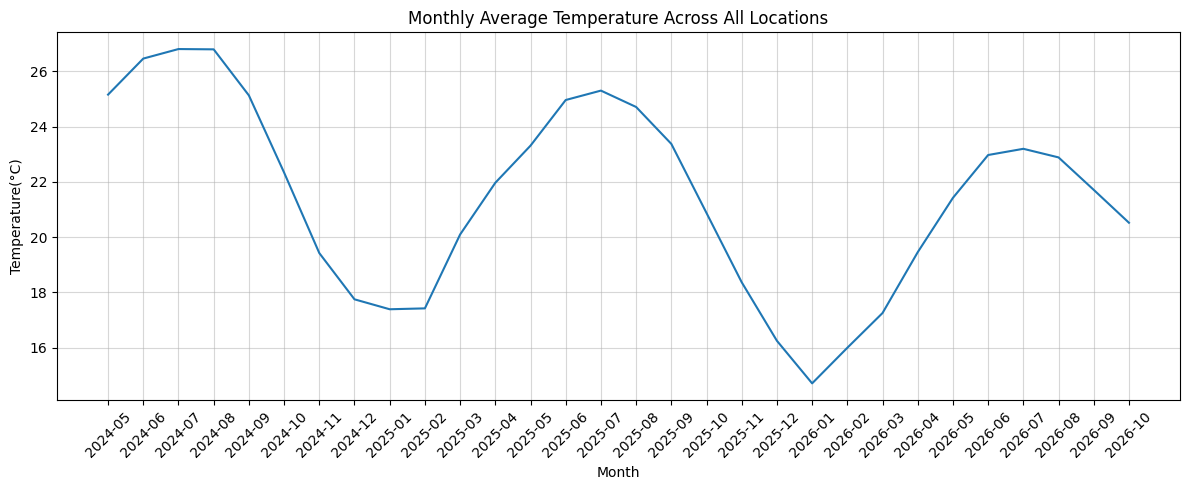

In [ ]:
monthly_trend = weather_df.groupby(pd.to_datetime(weather_df['last_updated']).dt.to_period('M'))['temperature_celsius'].mean()

plt.figure(figsize=(12,5))
plt.plot(monthly_trend.index.astype('str'),monthly_trend.values)

plt.title('Monthly Average Temperature Across All Locations')
plt.xlabel('Month')
plt.ylabel('Temperature(°C)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.grid(True,alpha=0.5)
plt.show()

## 10: Visualize monthly precipitation
This chart compares the total precipitation recorded in January, February, and so on, across all years and locations in your dataset.

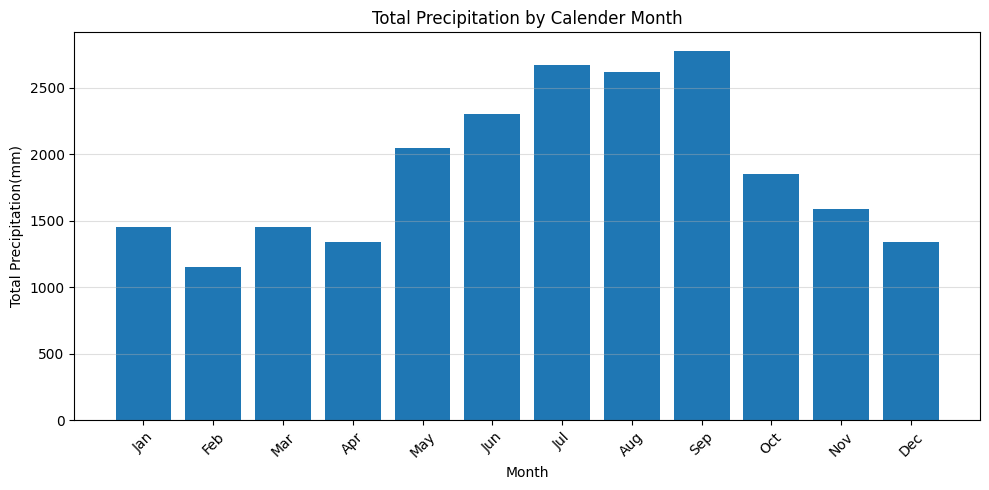

In [ ]:
plt.figure(figsize=(10,5))

plt.bar(monthly_summary['month'],monthly_summary['total_precipitation'])

plt.title('Total Precipitation by Calender Month')
plt.xlabel('Month')
plt.ylabel('Total Precipitation(mm)')
plt.xticks(rotation=45)
plt.grid(axis='y',alpha=0.4)

plt.tight_layout()
plt.show()

## 10: Create a temperature histogram
A histogram helps us understand which temperature ranges occur most frequently across your dataset.

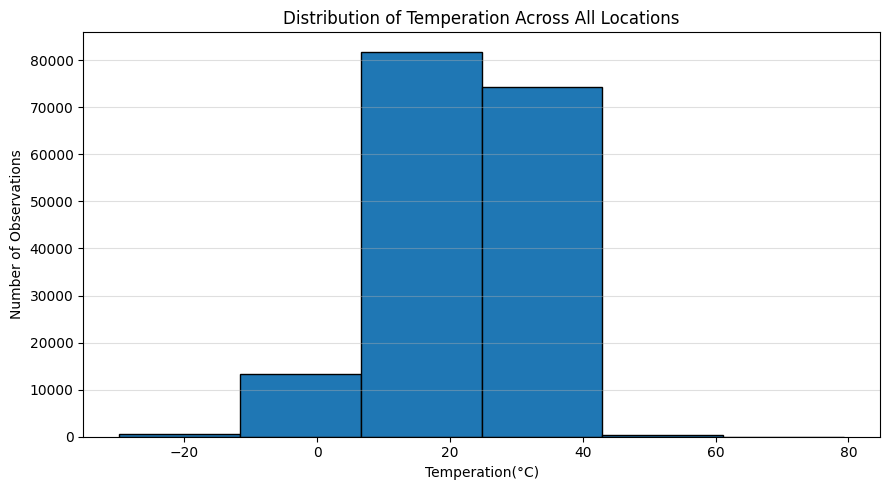

In [ ]:
plt.figure(figsize=(9,5))

plt.hist(weather_df['temperature_celsius'].dropna(), bins=6, edgecolor='black')

plt.title('Distribution of Temperation Across All Locations')
plt.xlabel('Temperation(°C)')
plt.ylabel('Number of Observations')
plt.grid(axis='y',alpha=0.4)

plt.tight_layout()
plt.show()

## 10. Seasonal Comparison Chart

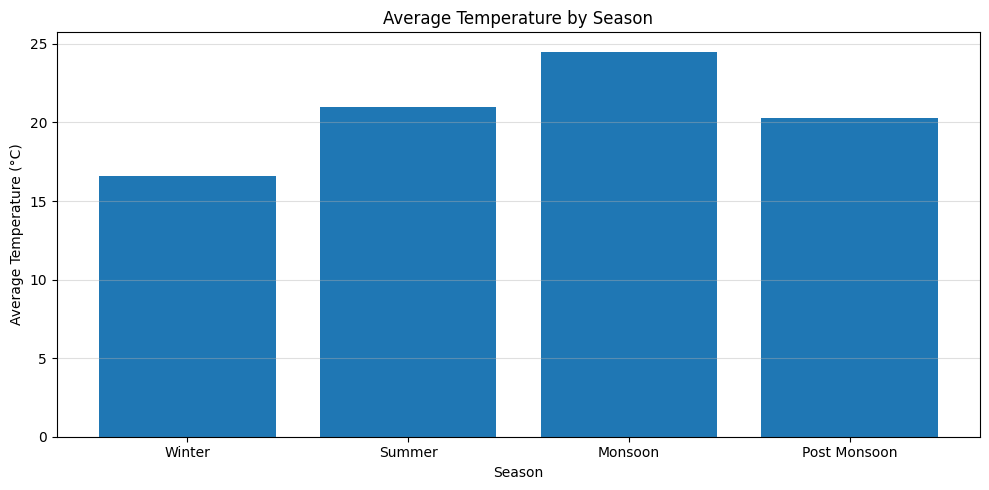

In [ ]:
plt.figure(figsize=(10,5))

plt.bar(seasonal_summary['season'],seasonal_summary['average_temperature'])

plt.title('Average Temperature by Season')
plt.xlabel('Season')
plt.ylabel('Average Temperature (°C)')
plt.grid(axis='y',alpha=0.4)

plt.tight_layout()
plt.show()

## 11: Identify extreme temperatures and heavy precipitation
We'll use percentile thresholds to identify unusually low or high temperatures and unusually high precipitation values in your dataset.
- Extreme temperature: At or below the 5th percentile, or at or above the 95th percentile.
- Heavy precipitation: At or above the 95th percentile of records with precipitation greater than zero.
These are statistical thresholds based on your dataset, not official weather-warning limits.

In [ ]:

# Step 11: Identify Extreme Weather Records

# Calculate temperature thresholds
temp_low = np.nanpercentile(weather_df["temperature_celsius"], 5)
temp_high = np.nanpercentile(weather_df["temperature_celsius"], 95)

# Calculate heavy rainfall threshold
wet_days = weather_df[weather_df["precip_mm"] > 0]["precip_mm"]

if len(wet_days) > 0:
    heavy_rain_threshold = np.nanpercentile(wet_days, 95)
else:
    heavy_rain_threshold = np.nan

# Find extreme temperatures
extreme_temperature = weather_df[
    (weather_df["temperature_celsius"] <= temp_low) |
    (weather_df["temperature_celsius"] >= temp_high)
]

# Find heavy rainfall records
if not np.isnan(heavy_rain_threshold):
    heavy_precipitation = weather_df[
        weather_df["precip_mm"] >= heavy_rain_threshold
    ]
else:
    heavy_precipitation = weather_df.iloc[0:0]

# Display results
print(f"Lowest temperature threshold: {temp_low:.2f} °C")
print(f"Highest temperature threshold: {temp_high:.2f} °C")
print(f"Heavy rainfall threshold: {heavy_rain_threshold:.2f} mm")

columns = ["last_updated", "location_name", "temperature_celsius",
           "humidity", "precip_mm"]

print("\nExtreme Temperature Records:")
display(extreme_temperature[columns].sort_values("temperature_celsius"))

print("\nHeavy Rainfall Records (Top 20):")
display(heavy_precipitation[columns].sort_values(
    "precip_mm", ascending=False
).head(20))


Lowest temperature threshold: 3.40 °C
Highest temperature threshold: 33.70 °C
Heavy rainfall threshold: 1.67 mm

Extreme Temperature Records:


,last_updated,location_name,temperature_celsius,humidity,precip_mm
118990,2026-01-18 15:00:00,Ulaanbaatar,-29.8,56.0,0.00
119182,2026-01-20 15:15:00,Ulaanbaatar,-28.9,62.0,0.00
121617,2026-02-02 10:00:00,Minsk,-26.9,83.0,0.00
118606,2026-01-16 15:15:00,Ulaanbaatar,-26.8,69.0,0.00
118801,2026-01-17 15:00:00,Ulaanbaatar,-25.9,69.0,0.00
...,...,...,...,...,...
8425,2024-06-27 16:15:00,Kuwait City,48.9,4.0,0.00
11145,2024-07-11 15:45:00,Baghdad,49.1,6.0,0.00
7460,2024-06-22 16:45:00,Baghdad,49.1,8.0,0.00
6896,2024-06-19 16:45:00,Kuwait City,49.2,4.0,0.00



Heavy Rainfall Records (Top 20):


,last_updated,location_name,temperature_celsius,humidity,precip_mm
162949,2026-09-03 01:45:00,Nassau,25.6,88.0,74.52
160138,2026-08-19 07:00:00,Niamey,23.5,92.0,49.65
33439,2024-11-05 04:00:00,Port Royal,27.0,89.0,42.24
164119,2026-09-09 02:00:00,Nassau,25.2,89.0,33.44
143416,2026-05-25 06:30:00,Freetown,25.4,83.0,31.57
22098,2024-09-07 19:00:00,Hanoi,26.2,89.0,27.82
81715,2025-07-11 08:30:00,Bissau,25.2,100.0,27.40
30375,2024-10-20 04:30:00,Port Royal,27.1,89.0,26.38
92717,2025-09-05 08:00:00,Freetown,23.3,97.0,26.28
19431,2024-08-26 00:00:00,Suva,20.3,100.0,26.22


## 12: Identify weather extremes
We'll use Pandas idxmax() and idxmin() to find:
- Warmest record: The observation with the highest temperature.
- Coolest record: The observation with the lowest temperature.
- Wettest record: The observation with the highest precipitation.

In [ ]:
# Step 12: Find Extreme Weather Records

# Find the records
warmest = weather_df.loc[weather_df["temperature_celsius"].idxmax()]
coolest = weather_df.loc[weather_df["temperature_celsius"].idxmin()]
wettest = weather_df.loc[weather_df["precip_mm"].idxmax()]

# Select the columns to display
columns = ["last_updated", "location_name", "country",
           "temperature_celsius", "humidity", "precip_mm"]

# Display the results
print("Warmest Weather Record:")
display(warmest[columns].to_frame().T)

print("Coolest Weather Record:")
display(coolest[columns].to_frame().T)

print("Wettest Weather Record:")
display(wettest[columns].to_frame().T)

Warmest Weather Record:


,last_updated,location_name,country,temperature_celsius,humidity,precip_mm
137275,2026-04-24 18:30:00,Suva,Fiji Islands,79.3,7.0,0.99


Coolest Weather Record:


,last_updated,location_name,country,temperature_celsius,humidity,precip_mm
118990,2026-01-18 15:00:00,Ulaanbaatar,Mongolia,-29.8,56.0,0.0


Wettest Weather Record:


,last_updated,location_name,country,temperature_celsius,humidity,precip_mm
162949,2026-09-03 01:45:00,Nassau,Bahamas,25.6,88.0,74.52
